In [6]:
!pip install -q ultralytics pycocotools pandas matplotlib seaborn psutil

In [7]:
from pathlib import Path
import time
import random
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

In [8]:
BASE_DIR = Path.cwd()

DATASET_DIR = BASE_DIR / "datasets"
COCO_DIR = DATASET_DIR / "coco"

RESULTS_DIR = BASE_DIR / "results" / "detection"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 640
DEVICE = "cpu"

NUM_TEST_IMAGES = 500

print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Test images:", NUM_TEST_IMAGES)

Device: cpu
Image size: 640
Test images: 500


In [9]:
COCO_IMAGES = COCO_DIR / "val2017"

COCO_ANNOTATIONS = (
    COCO_DIR /
    "annotations" /
    "instances_val2017.json"
)

print("Images:", COCO_IMAGES)
print("Annotations:", COCO_ANNOTATIONS)

print("Images exist:", COCO_IMAGES.exists())
print("Annotations exist:", COCO_ANNOTATIONS.exists())

Images: C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\coco\val2017
Annotations: C:\Users\akars\Capstone\AI_Intruder_Capstone\datasets\coco\annotations\instances_val2017.json
Images exist: True
Annotations exist: True


In [10]:
from pycocotools.coco import COCO

coco = COCO(str(COCO_ANNOTATIONS))

person_category_id = coco.getCatIds(
    catNms=["person"]
)[0]

print("Person category ID:", person_category_id)

loading annotations into memory...
Done (t=0.52s)
creating index...
index created!
Person category ID: 1


In [11]:
person_image_ids = coco.getImgIds(
    catIds=[person_category_id]
)

print(
    "Images containing people:",
    len(person_image_ids)
)

Images containing people: 2693


In [12]:
person_images = []

for image_id in person_image_ids:

    image_info = coco.loadImgs(image_id)[0]

    image_path = COCO_IMAGES / image_info["file_name"]

    if image_path.exists():
        person_images.append(image_path)

random.seed(42)

test_images = random.sample(
    person_images,
    min(NUM_TEST_IMAGES, len(person_images))
)

print("Test images:", len(test_images))

Test images: 500


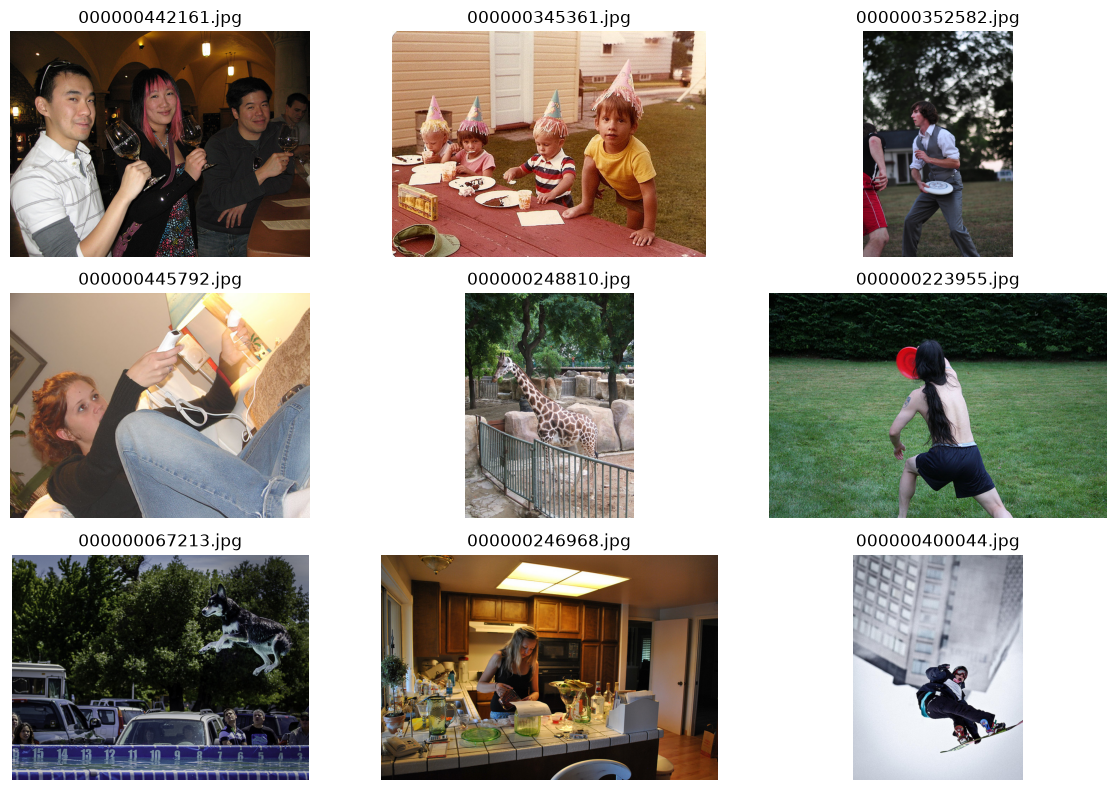

In [13]:
plt.figure(figsize=(12, 8))

for i, image_path in enumerate(test_images[:9]):

    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
MODEL_CONFIG = {
    "YOLO11n": "yolo11n.pt",
    "YOLO11s": "yolo11s.pt",
    "YOLO26n": "yolo26n.pt",
    "YOLO26s": "yolo26s.pt"
}

models = {}

for name, path in MODEL_CONFIG.items():

    print("Loading:", name)

    models[name] = YOLO(path)

print("All models loaded.")

Loading: YOLO11n
Loading: YOLO11s
Loading: YOLO26n
Loading: YOLO26s
All models loaded.


In [17]:
model = models["YOLO11n"]

results = model.predict(
    source=str(test_images[0]),
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    conf=0.25,
    verbose=False
)

results[0].show()

In [18]:
result = results[0]

boxes = result.boxes

person_boxes = []

for box, cls, conf in zip(
    boxes.xyxy,
    boxes.cls,
    boxes.conf
):

    if int(cls) == 0:

        person_boxes.append({
            "box": box.cpu().numpy(),
            "confidence": float(conf)
        })

print("People detected:", len(person_boxes))

People detected: 4


In [19]:
def benchmark_model(model, images, warmup=10):

    warmup_images = images[:warmup]
    benchmark_images = images[warmup:]

    # Warm-up
    for image in warmup_images:

        model.predict(
            source=str(image),
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )

    times = []

    for image in benchmark_images:

        start = time.perf_counter()

        model.predict(
            source=str(image),
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )

        end = time.perf_counter()

        times.append(end - start)

    times = np.array(times)

    mean_latency = times.mean()
    median_latency = np.median(times)
    p95_latency = np.percentile(times, 95)

    return {
        "Mean Latency (ms)": mean_latency * 1000,
        "Median Latency (ms)": median_latency * 1000,
        "P95 Latency (ms)": p95_latency * 1000,
        "FPS": 1 / mean_latency
    }

In [21]:
speed_results = []

for name, model in models.items():

    print("Benchmarking:", name)

    metrics = benchmark_model(
        model,
        test_images
    )

    metrics["Model"] = name

    speed_results.append(metrics)

speed_df = pd.DataFrame(speed_results)

speed_df

Benchmarking: YOLO11n
Benchmarking: YOLO11s
Benchmarking: YOLO26n
Benchmarking: YOLO26s


,Mean Latency (ms),Median Latency (ms),P95 Latency (ms),FPS,Model
0,71.532668,67.68150,113.04870,13.979627,YOLO11n
1,167.946273,164.39460,247.89596,5.954285,YOLO11s
2,73.765743,70.88620,114.29508,13.556428,YOLO26n
3,155.221290,150.21535,213.04423,6.442415,YOLO26s


In [22]:
model_info = []

for name, model in models.items():

    params = sum(
        p.numel()
        for p in model.model.parameters()
    )

    model_info.append({
        "Model": name,
        "Parameters": params
    })

model_info_df = pd.DataFrame(model_info)

model_info_df

,Model,Parameters
0,YOLO11n,2624080
1,YOLO11s,9458752
2,YOLO26n,2572280
3,YOLO26s,10009784


In [23]:
detection_results = speed_df.merge(
    model_info_df,
    on="Model"
)

detection_results

,Mean Latency (ms),Median Latency (ms),P95 Latency (ms),FPS,Model,Parameters
0,71.532668,67.68150,113.04870,13.979627,YOLO11n,2624080
1,167.946273,164.39460,247.89596,5.954285,YOLO11s,9458752
2,73.765743,70.88620,114.29508,13.556428,YOLO26n,2572280
3,155.221290,150.21535,213.04423,6.442415,YOLO26s,10009784


In [24]:
detection_results.to_csv(
    RESULTS_DIR / "detection_benchmark.csv",
    index=False
)

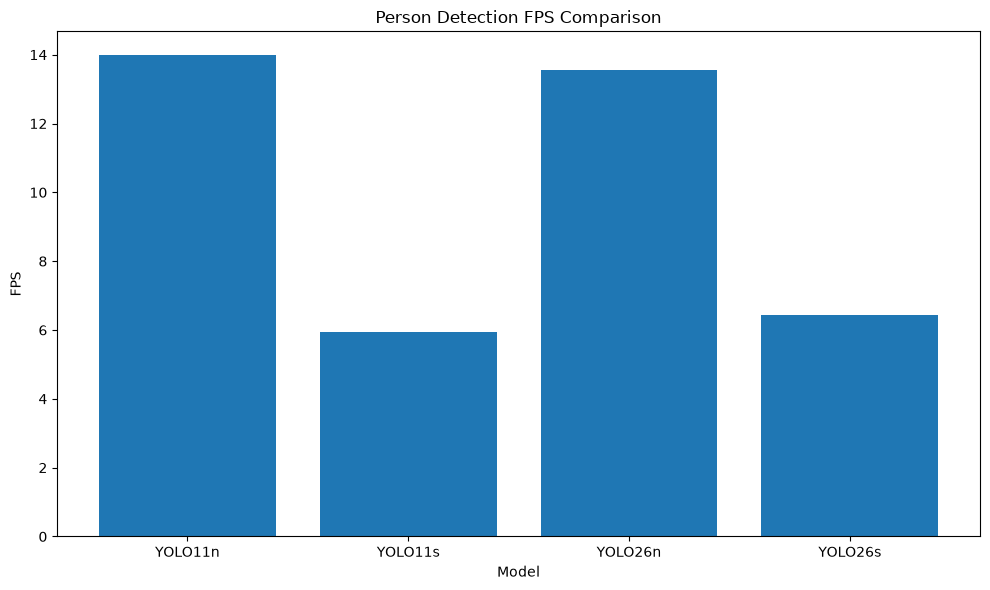

In [25]:
plt.figure(figsize=(10, 6))

plt.bar(
    detection_results["Model"],
    detection_results["FPS"]
)

plt.ylabel("FPS")
plt.xlabel("Model")
plt.title("Person Detection FPS Comparison")

plt.tight_layout()
plt.show()